# 🧠 The Attention Mechanism — A Complete Guide

> *From the problem that created it, to the math that drives it, to the code that implements it.*

---

## How This Notebook Is Organized

We follow a **problem → intuition → history → math → code → examples** flow:

| # | Section | What You'll Learn |
|---|---------|-------------------|
| 1 | **The Problem** | Why older models (RNN/LSTM seq2seq) hit a wall |
| 2 | **What Is Attention?** | The core intuition — library analogy, Q/K/V |
| 3 | **History & Evolution** | Bahdanau → Luong → Transformer attention |
| 4 | **The Math** | Formulas for every variant, step by step |
| 5 | **Self-Attention Deep Dive** | Full numerical walkthrough |
| 6 | **Multi-Head Attention** | Why one head isn't enough |
| 7 | **Positional Encoding** | How Transformers know word order |
| 8 | **Encoder-Decoder Architecture** | Putting it all together |
| 9 | **Keras / TensorFlow Code** | Working implementations |
| 10 | **Translation Examples** | English→French (easy) vs English→Hindi (hard) |
| 11 | **Summary** | Quick-reference recap |

---

# Section 1: The Problem — Why We Needed Attention

Before attention existed, the dominant architecture for tasks like machine translation was the **Sequence-to-Sequence (Seq2Seq)** model using RNNs or LSTMs.

Let's understand why it failed — and why that failure *demanded* a new mechanism.

## 1.1 The Seq2Seq Architecture (Pre-Attention Era)

A Seq2Seq model has two parts:

```
┌─────────────────────────────────────────────────┐
│                   ENCODER                        │
│  Reads input sentence word by word (left→right)  │
│  Compresses everything into ONE vector            │
│  Called the "context vector" or "thought vector"  │
└──────────────────────┬──────────────────────────┘
                       │
              context vector (fixed size!)
                       │
┌──────────────────────▼──────────────────────────┐
│                   DECODER                        │
│  Reads the single context vector                 │
│  Generates output sentence word by word           │
│  Must reconstruct ALL information from that       │
│  one vector!                                      │
└─────────────────────────────────────────────────┘
```

**The fundamental issue:** No matter how long the input sentence is — 5 words or 50 words — it gets squeezed into the **same fixed-size vector** (typically 256 or 512 dimensions).

This is called the **Information Bottleneck**.

## 1.2 Example: Why the Bottleneck Hurts

### Easy Case — English → French (both SVO languages)

English and French share the **Subject-Verb-Object** word order:

```
English:  "The cat    sits   on  the mat"
           Subject    Verb       Object
              ↓        ↓          ↓
French:   "Le chat  s'assoit sur le tapis"
           Subject    Verb       Object
```

The words map almost **one-to-one in the same order**. A fixed context vector can handle this reasonably well because the decoder just needs to output words in roughly the same sequence it received them.

✅ **Result:** Seq2Seq works *okay* for similar-structure languages.

---

### Hard Case — English → Hindi (SVO → SOV)

Now watch what happens with Hindi. English is **SVO**, Hindi is **SOV**:

```
English:  "Ram    eats     food"
           Subj   Verb     Obj     (SVO order)
            ↓       ╲      ╱ ↓
            ↓        ╳       ↓
            ↓       ╱ ╲      ↓
Hindi:    "राम    खाना    खाता है"
           Subj    Obj     Verb    (SOV order)
           (Ram)  (food)  (eats)
```

The verb and object **swap positions**! The decoder needs to:
- Output **"राम"** → look at position 1 (Ram) ✓
- Output **"खाना"** → reach *backwards* to position 3 (food) ✗
- Output **"खाता है"** → reach *backwards* to position 2 (eats) ✗

With a fixed context vector, there is **no mechanism** to say *"for THIS output word, emphasize THAT input position."*

❌ **Result:** The fixed vector fails because word order completely changes.

> **This is exactly the problem attention was invented to solve.**

## 1.3 The Bottleneck Gets Worse with Length

As sentences get longer, the fixed vector must store more and more information in the same number of dimensions:

| Sentence Length | Information to Store | Fixed Vector Size | Quality |
|-----------------|---------------------|-------------------|---------|
| 5 words | Low | 512-d | ✅ Good |
| 15 words | Medium | 512-d | ⚠️ Okay |
| 30 words | High | 512-d | ❌ Poor |
| 50+ words | Very High | 512-d | ❌❌ Very Poor |

Research showed BLEU scores (translation quality) **dropped dramatically** for sentences longer than ~20 words.

> **Key Insight:** The decoder should NOT use one identical summary for every output token. Instead, it should assign higher importance to the source words most relevant to the *current* target word. That selective focusing is **Attention**.

# Section 2: What Is Attention? — Core Intuition

Now that we understand the problem, let's build the intuition for the solution.

## 2.1 The Library Analogy — Query, Key, Value

Think of attention like searching a library:

| Concept | Library Analogy | In Attention |
|---------|----------------|--------------|
| **Query (Q)** | What you're looking for: "books about cooking" | What the current decoder token needs |
| **Key (K)** | Each book's catalogue tag: "Italian cuisine", "Python programming" | How each input token advertises itself |
| **Value (V)** | The actual content of the book you read | The information each input token contributes |

**The process:**
1. You walk in with a **Query** ("I want cooking books")
2. You compare your query against every book's **Key** (catalogue tags)
3. You find that "Italian cuisine" matches strongly, "Python programming" doesn't
4. You read the **Values** (actual content) of the matching books
5. You combine what you read, weighted by how relevant each book was

> **Attention does exactly this** — it finds which input words are most relevant to the current output word, then creates a weighted blend of their information.

## 2.2 The Four Steps of Attention

Every attention mechanism follows these four steps:

### Step 1: Score — How relevant is each input?
Compare the query against every key using a similarity function (e.g., dot product).

```
Query: "खाना" (the Hindi word for food being generated)
Score("Ram")  = 0.9   ← not very relevant
Score("eats") = 2.1   ← somewhat relevant  
Score("food") = 8.4   ← very relevant!
```

### Step 2: Normalize — Convert scores to weights via Softmax
Raw scores can be any number. Softmax squashes them into probabilities summing to 1.0:

```
Weights = softmax([0.9, 2.1, 8.4]) = [0.04, 0.18, 0.78]
                                        4%   18%   78%
```

### Step 3: Weighted Sum — Blend the values
Multiply each value vector by its weight and sum:

```
Context = 0.04 × V(Ram) + 0.18 × V(eats) + 0.78 × V(food)
```

The result is dominated by "food" (78%) — exactly what we need when translating "खाना"!

### Step 4: Use the context
This context vector is fed to the decoder along with the previous hidden state to generate the next word.

## 2.3 The Clean Separation of Concerns

Each token plays **three different roles** simultaneously through different learned projections:

- **Key** says: *"Here's what I am / what I contain"* — used for matching
- **Query** says: *"Here's what I'm looking for"* — used for searching
- **Value** says: *"Here's what you actually get from me"* — the content returned

> **Important:** Keys and Queries only exist to compute weights. Once the weights are decided, they are discarded. Only Values flow forward.

### Why Separate Key from Value?

A token can *advertise itself differently for matching* vs *what it contributes when selected*.

**Example:** The word "bank" in *"I deposited money at the bank."*
- Its **Key** encodes *"financial institution"* — helping queries about money find it
- Its **Value** carries its full rich embedding — grammatical role, position, semantic context

If Key and Value were the same vector, you'd be forced to make a token's "findability" identical to its "contribution." Separating them gives the model an extra degree of freedom.

### What's Inside a Value Vector?

$$V = \text{embedding} \times W_v$$

$W_v$ is a learned weight matrix. The model discovers through backpropagation what information to pack into Values so downstream layers can do their job well.

> **You never hand-specify it — the model discovers what to put there.**

# Section 3: History & Evolution of Attention

Attention wasn't invented overnight. It evolved through several key papers.

## 3.1 Before Attention: Pure Seq2Seq (Sutskever et al., 2014)

- Encoder RNN reads input → produces single context vector
- Decoder RNN generates output from that vector
- **Problem:** Information bottleneck for long sequences
- **Paper:** "Sequence to Sequence Learning with Neural Networks"

```
Input: w₁ w₂ w₃ ... wₙ → [Encoder RNN] → context vector → [Decoder RNN] → y₁ y₂ y₃ ...
                                              ↑
                                    ONE fixed vector for everything!
```

## 3.2 Additive Attention — Bahdanau et al. (2015)

**The paper that started it all:** *"Neural Machine Translation by Jointly Learning to Align and Translate"*

**Key Innovation:** Instead of one context vector, compute a **different** context for each decoder step.

**Score function (Additive / Concat):**

$$e_{i} = v^{a\top} \tanh(W_q \, q + W_k \, k_i)$$

- Concatenates query and key, passes through a small feedforward network
- Uses learned parameters: $W_q$, $W_k$, and $v^a$
- **Slower** due to extra parameters, but historically first
- Works when query and key have **different dimensions** ($d_q \neq d_k$)

**How it works:**
```
For each decoder step t:
  1. Take decoder hidden state sₜ (this is the Query)
  2. Compare with ALL encoder hidden states h₁...hₙ (these are Keys)
  3. eₜᵢ = vᵃᵀ tanh(Wq·sₜ + Wk·hᵢ)     ← Score each input
  4. αₜᵢ = softmax(eₜᵢ)                   ← Normalize to weights
  5. cₜ = Σ αₜᵢ · hᵢ                      ← Weighted sum (context)
  6. Use cₜ to help generate output word yₜ
```

## 3.3 Dot-Product Attention — Luong et al. (2015)

**Paper:** *"Effective Approaches to Attention-based Neural Machine Translation"*

**Key Innovation:** Simpler, faster scoring — just use a dot product!

**Score function:**

$$e_{i} = q^\top k_i$$

- No extra parameters needed — just multiply query and key
- **Fast** and efficient
- Requires query and key to have the **same dimensionality**
- Works well at moderate dimensions

**Three variants Luong proposed:**

| Variant | Score Function | Notes |
|---------|---------------|-------|
| **Dot** | $q^\top k_i$ | Simplest, no extra params |
| **General** | $q^\top W k_i$ | Adds a learned weight matrix |
| **Concat** | $v^\top \tanh(W[q; k_i])$ | Similar to Bahdanau |

## 3.4 Scaled Dot-Product Attention — Vaswani et al. (2017)

**The Transformer paper:** *"Attention Is All You Need"*

**Key Innovation:** Scale the dot product + remove recurrence entirely!

**Score function:**

$$e_{i} = \frac{q^\top k_i}{\sqrt{d_k}}$$

**Full attention formula (the most important equation in modern NLP):**

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V$$

### Why Scale by $\sqrt{d_k}$?

In $d_k$ dimensions, the variance of $q^\top k$ grows as $d_k$. Dividing by $\sqrt{d_k}$ restores unit variance:

| Without Scaling | With Scaling (÷ $\sqrt{d_k}$) |
|---|---|
| Scores grow large → softmax saturates | Scores stay moderate → soft distribution |
| One weight ≈ 1.0, rest ≈ 0.0 | Weights spread meaningfully |
| Gradient ≈ 0 → model stops learning | Gradients flow → model learns |

### Why This Was Revolutionary

The Transformer showed you can build a **complete model using ONLY attention** — no RNNs, no LSTMs, no convolutions. This made training:
- **Massively parallel** (no sequential dependency)
- **Better at long-range dependencies** (direct connections between all positions)
- **Faster to train** (GPUs love matrix multiplications)

## 3.5 Timeline Summary

```
2014: Pure Seq2Seq (Sutskever)     → Fixed context vector, information bottleneck
  │
2015: Additive Attention (Bahdanau) → Dynamic context! But slow (feedforward scoring)
  │
2015: Dot-Product Attention (Luong) → Faster scoring, multiple variants
  │
2017: Scaled Dot-Product (Vaswani)  → Scaling fix + Self-Attention + Multi-Head
  │                                   → "Attention Is All You Need" → Transformers!
  │
2018+: BERT, GPT, T5, etc.         → Transformer-based models dominate NLP
```

# Section 4: The Mathematics of Attention

Now that we have the intuition and history, let's formalize everything.

## 4.1 Notation Reference

| Symbol | Meaning |
|---|---|
| $q$ | Query vector — what this token is looking for |
| $k_i$ | Key vector of token $i$ — how that token can be matched |
| $v_i$ | Value vector of token $i$ — what that token contributes |
| $e_i$ | Raw score between $q$ and $k_i$ |
| $\alpha_i$ | Attention weight after softmax |
| $c$ | Context vector: weighted sum $\sum \alpha_i v_i$ |
| $d_k$ | Dimension of the keys / queries |
| $d_v$ | Dimension of the values |
| $h$ | Number of heads in multi-head attention |
| $W^Q, W^K, W^V$ | Learned projection matrices |
| $W^O$ | Output projection matrix in multi-head attention |

## 4.2 The General Attention Formula

**Step 1 — Compute scores:**
$$e_i = \text{score}(q, k_i)$$

**Step 2 — Normalize via softmax:**
$$\alpha_i = \frac{\exp(e_i)}{\sum_{j=1}^{n} \exp(e_j)}$$

**Step 3 — Weighted sum of values:**
$$c = \sum_{i=1}^{n} \alpha_i \, v_i$$

### Score Functions Compared

| Method | Formula | Parameters | Speed |
|--------|---------|------------|-------|
| Additive (Bahdanau) | $v^{a\top} \tanh(W_q q + W_k k_i)$ | $W_q, W_k, v^a$ | Slow |
| Dot-Product (Luong) | $q^\top k_i$ | None | Fast |
| Scaled Dot-Product | $\frac{q^\top k_i}{\sqrt{d_k}}$ | None | Fast |
| General (Luong) | $q^\top W k_i$ | $W$ | Medium |

## 4.3 Scaled Dot-Product Attention — Matrix Form

In practice, we compute attention for **all queries simultaneously** using matrices:

$$Q = XW^Q \quad \text{(all queries)}$$
$$K = XW^K \quad \text{(all keys)}$$
$$V = XW^V \quad \text{(all values)}$$

**Shapes:**
- $X$: $(n \times d_{\text{model}})$ — input sequence
- $W^Q, W^K$: $(d_{\text{model}} \times d_k)$ — projection matrices
- $W^V$: $(d_{\text{model}} \times d_v)$ — value projection
- $Q, K$: $(n \times d_k)$
- $V$: $(n \times d_v)$

**Score matrix:**
$$S = \frac{QK^\top}{\sqrt{d_k}} \quad \text{shape: } (n \times n)$$

Each entry $S_{ij}$ = how much token $i$ attends to token $j$.

**Weight matrix:**
$$A = \text{softmax}(S) \quad \text{shape: } (n \times n)$$

Each row sums to 1.

**Output:**
$$\text{Attention}(Q, K, V) = A \cdot V \quad \text{shape: } (n \times d_v)$$

Each output row is a weighted combination of all value vectors.

## 4.4 Reading the Full Formula as One Sentence

$$\boxed{\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V}$$

> **In plain English:** "For each query, compute how similar it is to every key (dot product), scale down to prevent gradient issues (divide by √dₖ), convert to probabilities (softmax), then use those probabilities to take a weighted average of the values."

**The elegance:** Every step is differentiable, so the model learns:
1. *Which queries to make*
2. *What keys/values to expose*

...entirely through backpropagation — no hand-coded rules about which words should attend to which.

# Section 5: Self-Attention — Complete Numerical Walkthrough

## 5.1 What Makes Self-Attention Special?

Self-attention is **not** a different scoring mechanism — it is a different **source** of Q, K, V.

In regular (cross-)attention:
- Q comes from the **decoder**
- K, V come from the **encoder**

In **self-attention:**
- Q, K, V all come from the **same** input sequence!

$$Q = X W^Q, \quad K = X W^K, \quad V = X W^V$$

> Every token attends to every other token **in the same sequence**, including itself.

This is what makes Transformers so powerful — each word can directly look at every other word to build a rich, context-aware representation.

## 5.2 Step-by-Step: "Ram eats mango"

### Starting Point: Input Embeddings

Each word is embedded into a vector. Let $d_{\text{model}} = 4$:

```
x₁ (Ram)   = [0.2,  0.5, -0.3,  0.1]
x₂ (eats)  = [0.1, -0.2,  0.4,  0.3]
x₃ (mango) = [-0.1, 0.3,  0.2, -0.2]
```

$$X = \begin{bmatrix} 0.2 & 0.5 & -0.3 & 0.1 \\ 0.1 & -0.2 & 0.4 & 0.3 \\ -0.1 & 0.3 & 0.2 & -0.2 \end{bmatrix} \quad \text{shape: } 3 \times 4$$

### Step 1: Project to Q, K, V

Using learned weight matrices $W^Q, W^K, W^V$ (each shape $4 \times 2$, so $d_k = 2$):

$$Q = XW^Q = \begin{bmatrix} q_1 \\ q_2 \\ q_3 \end{bmatrix} \approx \begin{bmatrix} 0.11 & 0.12 \\ 0.03 & -0.01 \\ 0.08 & 0.05 \end{bmatrix}$$

$$K = XW^K = \begin{bmatrix} k_1 \\ k_2 \\ k_3 \end{bmatrix} \approx \begin{bmatrix} 0.28 & 0.19 \\ 0.25 & 0.22 \\ 0.22 & 0.21 \end{bmatrix}$$

$$V = XW^V = \begin{bmatrix} v_1 \\ v_2 \\ v_3 \end{bmatrix} \approx \begin{bmatrix} 0.15 & 0.32 \\ 0.20 & -0.10 \\ 0.12 & 0.18 \end{bmatrix}$$

### Step 2: Compute Attention Scores

$$S = QK^\top = \begin{bmatrix} q_1 \cdot k_1 & q_1 \cdot k_2 & q_1 \cdot k_3 \\ q_2 \cdot k_1 & q_2 \cdot k_2 & q_2 \cdot k_3 \\ q_3 \cdot k_1 & q_3 \cdot k_2 & q_3 \cdot k_3 \end{bmatrix}$$

Each entry answers: "How much should token $i$ attend to token $j$?"

### Step 3: Scale

$$S_{\text{scaled}} = \frac{S}{\sqrt{d_k}} = \frac{S}{\sqrt{2}} \approx \frac{S}{1.414}$$

### Step 4: Softmax (row-wise)

Each row becomes a probability distribution:

```
Row 1 (Ram attends to):    [0.34, 0.33, 0.33] → Ram looks at everything roughly equally
Row 2 (eats attends to):   [0.35, 0.32, 0.33] → eats focuses slightly more on Ram (subject)
Row 3 (mango attends to):  [0.33, 0.34, 0.33] → mango looks everywhere
```

### Step 5: Weighted Sum of Values

$$Z = A \cdot V$$

For "eats" (row 2):
$$z_2 = 0.35 \times v_{\text{Ram}} + 0.32 \times v_{\text{eats}} + 0.33 \times v_{\text{mango}}$$

> **Result:** Each word's new representation now contains information from the **entire sentence**, weighted by relevance.

### What Conceptually Happened

For each word:
1. **Ask:** What am I looking for? (Query)
2. **Compare:** With all words (Keys)  
3. **Decide:** Importance weights (Softmax)
4. **Collect:** Useful information (Values)
5. **Build:** New, context-enriched representation

## 5.3 Matrix Form — Efficient Computation

Instead of word-by-word, everything happens in one matrix operation:

$$\text{Self-Attention}(X) = \text{softmax}\!\left(\frac{(XW^Q)(XW^K)^\top}{\sqrt{d_k}}\right)(XW^V)$$

This is why Transformers are so fast — the entire operation is a series of **matrix multiplications** that GPUs handle brilliantly.

### Key Insight

Self-attention is NOT selecting one word. Instead:

> It builds a **new representation of each word** by mixing information from all words, weighted by learned relevance scores.

Before self-attention: each word only knows itself.
After self-attention: each word carries information about the full sentence.

# Section 6: Multi-Head Attention — Why One Head Isn't Enough

## 6.1 The Problem with Single-Head Attention

Imagine "The bank director sat on the bench."

To understand "bank," you need:
- **Perspective 1:** Financial institution? (context from "director")
- **Perspective 2:** River bank? (context from "bench")
- **Perspective 3:** Relation to "sat"? (positional context)

A single attention head computes **ONE** set of weights — a compromise that doesn't optimize for any single pattern:

```
Single head weights for "eats" in "Ram eats mango":
  [0.332, 0.335, 0.333]  ← Bland average, no strong focus!
```

We need **multiple perspectives** simultaneously.

## 6.2 The Solution: Run Multiple Attention Heads in Parallel

### Mathematical Formulation

For $H$ heads with dimension $d_k = d_{\text{model}} / H$:

**Each head h:**
$$\text{head}_h = \text{Attention}(XW_h^Q, \; XW_h^K, \; XW_h^V)$$

Each head has its **own** learned projection matrices $W_h^Q, W_h^K, W_h^V$.

**Concatenate all heads:**
$$\text{MultiHead}(X) = \text{Concat}(\text{head}_1, \ldots, \text{head}_H) \; W^O$$

**Complete formula:**
$$\boxed{\text{MultiHead}(Q, K, V) = \text{Concat}(\text{head}_1, \ldots, \text{head}_H) \; W^O}$$
$$\text{where } \text{head}_i = \text{Attention}(QW_i^Q, \; KW_i^K, \; VW_i^V)$$

### What Each Head Learns

Different heads automatically learn to focus on different linguistic relationships:

| Head | What It Learns | Example |
|------|---------------|---------|
| Head 1 | Subject-verb agreement | "eats" → heavy weight on "Ram" |
| Head 2 | Object relationships | "eats" → heavy weight on "mango" |
| Head 3 | Positional / syntactic | "eats" → weight on nearby words |
| Head 4+ | Other patterns | Coreference, negation, etc. |

## 6.3 Concrete Example: H = 3

Input: "Ram eats mango" with $d_{\text{model}} = 6$, $H = 3$, so $d_k = 6/3 = 2$.

**Head 1 (Subject attention):**
```
Weights for "eats": [0.70, 0.20, 0.10]  ← Focuses on Ram (who eats?)
Output: head₁ = 2-dim vector emphasizing subject
```

**Head 2 (Object attention):**
```
Weights for "eats": [0.10, 0.25, 0.65]  ← Focuses on mango (what's eaten?)
Output: head₂ = 2-dim vector emphasizing object
```

**Head 3 (Self-identity):**
```
Weights for "eats": [0.05, 0.85, 0.10]  ← Focuses on eats itself (verb identity)
Output: head₃ = 2-dim vector emphasizing verb
```

**Concatenate:** $[\text{head}_1 ; \text{head}_2 ; \text{head}_3]$ = 6-dim vector

**Project:** Multiply by $W^O$ (6×6) to get final 6-dim output.

> The final output for "eats" now encodes: who is doing the eating (from head 1), what is being eaten (from head 2), and the verb identity (from head 3) — **all simultaneously!**

### Dimension Accounting

| Component | Shape | Notes |
|-----------|-------|-------|
| Input $X$ | $(n, d_{\text{model}})$ | e.g., (3, 512) |
| $W_h^Q, W_h^K, W_h^V$ | $(d_{\text{model}}, d_k)$ | e.g., (512, 64) per head |
| Each $\text{head}_h$ | $(n, d_k)$ | e.g., (3, 64) |
| Concat of all heads | $(n, H \cdot d_k) = (n, d_{\text{model}})$ | e.g., (3, 512) |
| $W^O$ | $(d_{\text{model}}, d_{\text{model}})$ | e.g., (512, 512) |
| **Final output** | $(n, d_{\text{model}})$ | **Same shape as input!** |

# Section 7: Positional Encoding — How Transformers Know Word Order

## 7.1 The Problem: Attention is Position-Agnostic

Attention mechanism doesn't inherently know about positions.

**Example:** "Ram eats mango" vs "mango eats Ram"

Without positional information, both have the same three token embeddings, just reordered. Self-attention would produce **identical** results since it's a set operation — it only cares about what tokens exist, not where they are.

But "Ram eats mango" and "mango eats Ram" have completely different meanings!

> **We need to inject position information into the embeddings.**

## 7.2 The Sinusoidal Solution

The original Transformer uses sine and cosine functions at different frequencies:

$$PE(\text{pos}, 2i) = \sin\!\left(\frac{\text{pos}}{10000^{2i/d_{\text{model}}}}\right)$$

$$PE(\text{pos}, 2i+1) = \cos\!\left(\frac{\text{pos}}{10000^{2i/d_{\text{model}}}}\right)$$

Where:
- $\text{pos}$ = position in the sequence (0, 1, 2, ...)
- $i$ = dimension index
- $d_{\text{model}}$ = embedding dimension

**Final input to the Transformer:**
$$\text{input} = \text{token\_embedding} + \text{positional\_encoding}$$

## 7.3 Concrete Example: $d_{\text{model}} = 4$

**Calculate frequencies:**

$$\theta_0 = \frac{1}{10000^{0/4}} = \frac{1}{1} = 1 \quad \text{(fast oscillation)}$$
$$\theta_1 = \frac{1}{10000^{2/4}} = \frac{1}{100} = 0.01 \quad \text{(slow oscillation)}$$

**Positional encodings:**

| pos | dim 0 ($\sin$) | dim 1 ($\cos$) | dim 2 ($\sin$) | dim 3 ($\cos$) |
|-----|-------|--------|--------|--------|
| 0 | 0.000 | 1.000 | 0.000 | 1.000 |
| 1 | 0.841 | 0.540 | 0.010 | 1.000 |
| 2 | 0.909 | −0.416 | 0.020 | 1.000 |
| 3 | 0.141 | −0.990 | 0.030 | 1.000 |

**Notice:**
- Dimensions 0,1: Oscillate **rapidly** (frequency = 1) — capture fine position differences
- Dimensions 2,3: Oscillate **slowly** (frequency = 0.01) — capture coarse position
- Each position has a **unique** encoding

## 7.4 Why Sine and Cosine?

**Key property:** Relative positions can be expressed as linear transformations.

$$PE(\text{pos} + k) = f(PE(\text{pos}), k)$$

Using the identity $\sin(A+B) = \sin A \cos B + \cos A \sin B$:

The model can learn to attend to **relative positions** (e.g., "2 words ago") rather than absolute positions. This helps with generalization to different sequence lengths.

# Section 8: The Complete Transformer — Encoder-Decoder Architecture

## 8.1 Overall Structure

```
INPUT: "Ram eats mango"
         ↓
    ┌─────────────────────────────┐
    │      ENCODER STACK          │
    │   (N layers, e.g. N=6)      │
    │   Reads and understands     │
    │   the input sequence        │
    └────────────┬────────────────┘
                 ↓
    ENCODER OUTPUT (rich representation)
                 ↓
    ┌─────────────────────────────┐
    │      DECODER STACK          │
    │   (N layers, e.g. N=6)      │
    │   Generates output token    │
    │   by token, using encoder   │
    └────────────┬────────────────┘
                 ↓
    OUTPUT: "राम खाना खाता है"
```

**Two distinct components:**
1. **Encoder:** Processes input, builds deep understanding
2. **Decoder:** Generates output using encoder's understanding

## 8.2 Single Encoder Layer

Each encoder layer has **2 sub-layers:**

```
INPUT: (batch, seq_len, d_model)
         ↓
    ┌──────────────────────────────────────┐
    │   MULTI-HEAD SELF-ATTENTION          │
    │   (each position sees all inputs)    │
    └────────────┬─────────────────────────┘
                 ↓
    ┌──────────────────────────────────────┐
    │   ADD & LAYER NORM                   │
    │   output = LayerNorm(input + attn)   │
    └────────────┬─────────────────────────┘
                 ↓
    ┌──────────────────────────────────────┐
    │   FEED-FORWARD NETWORK               │
    │   Dense(d_ff) → ReLU → Dense(d_model)│
    │   (position-wise, fully connected)   │
    └────────────┬─────────────────────────┘
                 ↓
    ┌──────────────────────────────────────┐
    │   ADD & LAYER NORM                   │
    │   output = LayerNorm(input + ffn)    │
    └────────────┬─────────────────────────┘
                 ↓
OUTPUT: (batch, seq_len, d_model)  ← Same shape!
```

**Equations:**
$$\text{attn\_out} = \text{MultiHeadAttention}(x, x, x) \quad \text{(self-attention: Q=K=V=x)}$$
$$x' = \text{LayerNorm}(x + \text{attn\_out}) \quad \text{(residual + norm)}$$
$$\text{ffn\_out} = W_2 \cdot \text{ReLU}(W_1 \cdot x' + b_1) + b_2$$
$$x'' = \text{LayerNorm}(x' + \text{ffn\_out}) \quad \text{(residual + norm)}$$

## 8.3 Single Decoder Layer

Each decoder layer has **3 sub-layers** (one extra compared to encoder):

```
INPUT: (batch, target_len, d_model)
         ↓
    ┌──────────────────────────────────────┐
    │   MASKED MULTI-HEAD SELF-ATTENTION   │
    │   (can only see previous positions!) │
    └────────────┬─────────────────────────┘
                 ↓
    ADD & LAYER NORM
                 ↓
    ┌──────────────────────────────────────┐
    │   CROSS-ATTENTION                    │
    │   Q = decoder, K = encoder,          │
    │   V = encoder                        │
    │   (decoder looks at encoder output)  │
    └────────────┬─────────────────────────┘
                 ↓
    ADD & LAYER NORM
                 ↓
    ┌──────────────────────────────────────┐
    │   FEED-FORWARD NETWORK               │
    └────────────┬─────────────────────────┘
                 ↓
    ADD & LAYER NORM
                 ↓
OUTPUT: (batch, target_len, d_model)
```

### Three Types of Attention in a Transformer

| Type | Where | Q from | K, V from | Purpose |
|------|-------|--------|-----------|---------|
| **Encoder Self-Attention** | Encoder | Input | Input | Each input word sees all input words |
| **Masked Self-Attention** | Decoder | Output | Output | Each output word sees only *previous* output words |
| **Cross-Attention** | Decoder | Output | Encoder | Output words look at input words |

> **Why masked?** During training, the decoder must not cheat by looking at future target words. The mask sets future positions to $-\infty$ before softmax, making their weights zero.

## 8.4 Big Picture: From Attention to Transformer

```
2014: Seq2Seq         → One context vector (bottleneck!)
         ↓
2015: + Attention     → Dynamic context per decoder step
         ↓
2017: Transformer     → ONLY attention, no RNN at all!
         ↓
Architecture:
    • Self-attention   → Words understand each other within a sequence
    • Multi-head       → Multiple perspectives simultaneously
    • Positional enc.  → Word order information
    • Residual + Norm  → Deep network stability
    • Feed-forward     → Non-linear transformation per position
    • Encoder-Decoder  → Input understanding + output generation
```

> A Transformer is built on one simple principle: **Replace recurrence (RNN) with attention.**

# Section 9: Keras / TensorFlow Implementation

Now we move from concept to code. We'll build everything from scratch, starting small and gradually building toward a Transformer-style encoder.

## 9.1 Setup & Imports

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import time

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {len(tf.config.list_physical_devices('GPU')) > 0}")

TensorFlow version: 2.20.0
GPU available: False


## 9.2 Scaled Dot-Product Attention from Scratch

In [ ]:
class ScaledDotProductAttention(layers.Layer):
    """
    Implements: Attention(Q, K, V) = softmax(QK^T / sqrt(d_k)) V

    This is the fundamental building block of all Transformer attention.
    """
    def call(self, Q, K, V, mask=None):
        d_k = tf.cast(tf.shape(K)[-1], tf.float32)

        # Step 1: Compute attention scores
        scores = tf.matmul(Q, K, transpose_b=True)  # QK^T

        # Step 2: Scale
        scores = scores / tf.math.sqrt(d_k)          # / sqrt(d_k)

        # Step 3: Apply mask (optional - for decoder)
        if mask is not None:
            scores += (mask * -1e9)

        # Step 4: Softmax → attention weights
        weights = tf.nn.softmax(scores, axis=-1)

        # Step 5: Weighted sum of values
        output = tf.matmul(weights, V)

        return output, weights

### Quick Test: See Attention in Action

In [ ]:
# Create simple Q, K, V tensors
np.random.seed(42)
seq_len, d_k = 4, 8

Q = tf.random.normal((1, 1, seq_len, d_k))  # (batch, heads, seq, d_k)
K = tf.random.normal((1, 1, seq_len, d_k))
V = tf.random.normal((1, 1, seq_len, d_k))

sdpa = ScaledDotProductAttention()
output, weights = sdpa(Q, K, V)

print("Attention weights (each row sums to 1.0):")
print(np.round(weights.numpy()[0, 0], 3))
print(f"\nRow sums: {weights.numpy()[0, 0].sum(axis=-1)}")
print(f"\nOutput shape: {output.shape}")

Attention weights (each row sums to 1.0):
[[0.094 0.111 0.074 0.721]
 [0.25  0.404 0.212 0.135]
 [0.081 0.671 0.232 0.016]
 [0.076 0.138 0.083 0.703]]

Row sums: [1.        1.        0.9999999 1.       ]

Output shape: (1, 1, 4, 8)


## 9.3 Multi-Head Attention Layer

In [ ]:
class MultiHeadAttention(layers.Layer):
    """
    Runs h independent attention heads in parallel, then concatenates.

    MultiHead(Q, K, V) = Concat(head_1, ..., head_h) W^O
    where head_i = Attention(QW_i^Q, KW_i^K, VW_i^V)
    """
    def __init__(self, d_model, num_heads, **kwargs):
        super().__init__(**kwargs)
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

        self.num_heads = num_heads
        self.d_model = d_model
        self.depth = d_model // num_heads  # d_k per head

        # Learned projection matrices
        self.wq = layers.Dense(d_model)  # W^Q
        self.wk = layers.Dense(d_model)  # W^K
        self.wv = layers.Dense(d_model)  # W^V
        self.wo = layers.Dense(d_model)  # W^O (output projection)

        self.attention = ScaledDotProductAttention()

    def split_heads(self, x, batch_size):
        """Split the last dimension into (num_heads, depth)."""
        x = tf.reshape(x, (batch_size, -1, self.num_heads, self.depth))
        return tf.transpose(x, perm=[0, 2, 1, 3])  # (batch, heads, seq, depth)

    def call(self, Q, K, V, mask=None):
        batch_size = tf.shape(Q)[0]

        # Project to Q, K, V
        q = self.wq(Q)  # (batch, seq, d_model)
        k = self.wk(K)
        v = self.wv(V)

        # Split into multiple heads
        q = self.split_heads(q, batch_size)  # (batch, heads, seq, depth)
        k = self.split_heads(k, batch_size)
        v = self.split_heads(v, batch_size)

        # Apply attention
        attn_output, attn_weights = self.attention(q, k, v, mask)

        # Concatenate heads
        attn_output = tf.transpose(attn_output, perm=[0, 2, 1, 3])
        concat = tf.reshape(attn_output, (batch_size, -1, self.d_model))

        # Final linear projection
        output = self.wo(concat)

        return output, attn_weights

### Test Multi-Head Attention

In [ ]:
# Test with h=4 heads
d_model, num_heads, seq_len = 64, 4, 5

mha = MultiHeadAttention(d_model=d_model, num_heads=num_heads)
x = tf.random.normal((2, seq_len, d_model))  # batch=2, seq=5, d=64

output, weights = mha(x, x, x)  # Self-attention: Q=K=V=x
print(f"Input shape:  {x.shape}")
print(f"Output shape: {output.shape}  ← Same as input!")
print(f"Weight shape: {weights.shape}  ← (batch, heads, seq, seq)")
print(f"\nHead 0 attention weights (for first sequence):")
print(np.round(weights.numpy()[0, 0], 3))

Input shape:  (2, 5, 64)
Output shape: (2, 5, 64)  ← Same as input!
Weight shape: (2, 4, 5, 5)  ← (batch, heads, seq, seq)

Head 0 attention weights (for first sequence):
[[0.519 0.138 0.212 0.092 0.038]
 [0.896 0.016 0.012 0.056 0.021]
 [0.107 0.257 0.364 0.107 0.166]
 [0.061 0.204 0.067 0.072 0.596]
 [0.202 0.339 0.253 0.055 0.15 ]]


## 9.4 Positional Encoding

In [ ]:
class PositionalEncoding(layers.Layer):
    """Sinusoidal positional encoding from 'Attention Is All You Need'."""

    def __init__(self, max_len=5000, d_model=64, **kwargs):
        super().__init__(**kwargs)
        self.d_model = d_model

        # Precompute positional encodings
        pe = np.zeros((max_len, d_model))
        position = np.arange(max_len)[:, np.newaxis]
        div_term = np.exp(np.arange(0, d_model, 2) * -(np.log(10000.0) / d_model))

        pe[:, 0::2] = np.sin(position * div_term)  # Even dimensions
        pe[:, 1::2] = np.cos(position * div_term)  # Odd dimensions

        self.pe = tf.constant(pe[np.newaxis, :, :], dtype=tf.float32)

    def call(self, x):
        seq_len = tf.shape(x)[1]
        return x + self.pe[:, :seq_len, :]

### Visualize Positional Encodings

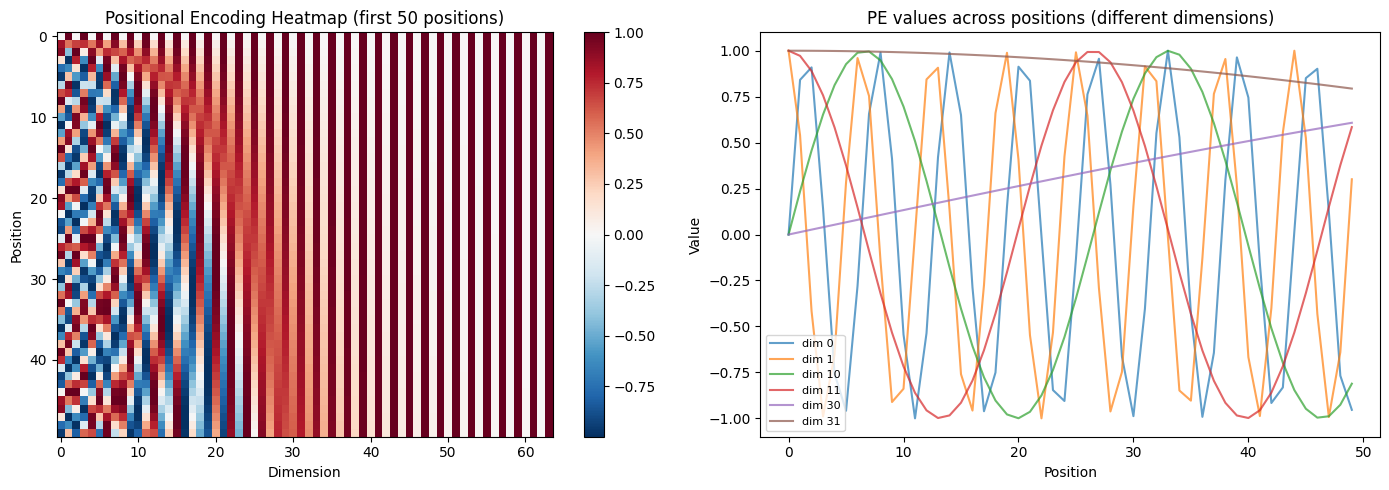

Notice: Low dimensions oscillate fast, high dimensions oscillate slowly.
Each position gets a unique 'fingerprint'!


In [ ]:
# Visualize the sinusoidal patterns
d_model = 64
pe_layer = PositionalEncoding(max_len=100, d_model=d_model)

# Get positional encodings (pass zero input)
dummy = tf.zeros((1, 100, d_model))
pe_values = pe_layer(dummy).numpy()[0]  # (100, 64)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Heatmap
im = axes[0].imshow(pe_values[:50, :], aspect='auto', cmap='RdBu_r')
axes[0].set_xlabel('Dimension')
axes[0].set_ylabel('Position')
axes[0].set_title('Positional Encoding Heatmap (first 50 positions)')
plt.colorbar(im, ax=axes[0])

# Line plot for specific dimensions
for dim in [0, 1, 10, 11, 30, 31]:
    axes[1].plot(pe_values[:50, dim], label=f'dim {dim}', alpha=0.7)
axes[1].set_xlabel('Position')
axes[1].set_ylabel('Value')
axes[1].set_title('PE values across positions (different dimensions)')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()
print("Notice: Low dimensions oscillate fast, high dimensions oscillate slowly.")
print("Each position gets a unique 'fingerprint'!")

## 9.5 Transformer Encoder Layer

In [ ]:
class TransformerEncoderLayer(layers.Layer):
    """One layer of the Transformer encoder."""

    def __init__(self, d_model, num_heads, d_ff, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)

        # Sub-layer 1: Multi-head self-attention
        self.mha = MultiHeadAttention(d_model, num_heads)
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout1 = layers.Dropout(dropout_rate)

        # Sub-layer 2: Feed-forward network
        self.ffn = keras.Sequential([
            layers.Dense(d_ff, activation='relu'),  # Expand
            layers.Dense(d_model)                     # Project back
        ])
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.dropout2 = layers.Dropout(dropout_rate)

    def call(self, x, training=False, mask=None):
        # Self-attention + residual + norm
        attn_output, attn_weights = self.mha(x, x, x, mask)
        attn_output = self.dropout1(attn_output, training=training)
        x = self.norm1(x + attn_output)  # Residual connection

        # Feed-forward + residual + norm
        ffn_output = self.ffn(x)
        ffn_output = self.dropout2(ffn_output, training=training)
        x = self.norm2(x + ffn_output)  # Residual connection

        return x, attn_weights

## 9.6 Complete Transformer Encoder

In [ ]:
class TransformerEncoder(keras.Model):
    """Complete Transformer encoder with embedding + positional encoding + N layers."""

    def __init__(self, vocab_size, d_model, num_heads, d_ff, num_layers,
                 max_len=512, dropout_rate=0.1, **kwargs):
        super().__init__(**kwargs)

        self.d_model = d_model
        self.embedding = layers.Embedding(vocab_size, d_model)
        self.pos_encoding = PositionalEncoding(max_len, d_model)
        self.dropout = layers.Dropout(dropout_rate)

        self.enc_layers = [
            TransformerEncoderLayer(d_model, num_heads, d_ff, dropout_rate)
            for _ in range(num_layers)
        ]

    def call(self, x, training=False, mask=None):
        # Token embedding + positional encoding
        x = self.embedding(x)
        x *= tf.math.sqrt(tf.cast(self.d_model, tf.float32))  # Scale embeddings
        x = self.pos_encoding(x)
        x = self.dropout(x, training=training)

        # Pass through N encoder layers
        attention_weights = {}
        for i, layer in enumerate(self.enc_layers):
            x, attn_w = layer(x, training=training, mask=mask)
            attention_weights[f'layer_{i}'] = attn_w

        return x, attention_weights

### Test the Complete Encoder

In [ ]:
# Build and test
encoder = TransformerEncoder(
    vocab_size=10000,
    d_model=64,
    num_heads=4,
    d_ff=128,
    num_layers=3
)

# Simulate input: batch of 2 sequences, each 10 tokens
sample_input = tf.random.uniform((2, 10), maxval=10000, dtype=tf.int32)
enc_output, enc_attn = encoder(sample_input, training=False)

print(f"Input shape:  {sample_input.shape}  (batch=2, seq=10)")
print(f"Output shape: {enc_output.shape}  (batch=2, seq=10, d_model=64)")
print(f"\nAttention layers: {list(enc_attn.keys())}")
print(f"Attention shape per layer: {enc_attn['layer_0'].shape}  (batch, heads, seq, seq)")

Input shape:  (2, 10)  (batch=2, seq=10)
Output shape: (2, 10, 64)  (batch=2, seq=10, d_model=64)

Attention layers: ['layer_0', 'layer_1', 'layer_2']
Attention shape per layer: (2, 4, 10, 10)  (batch, heads, seq, seq)


## 9.7 Visualize Attention Patterns

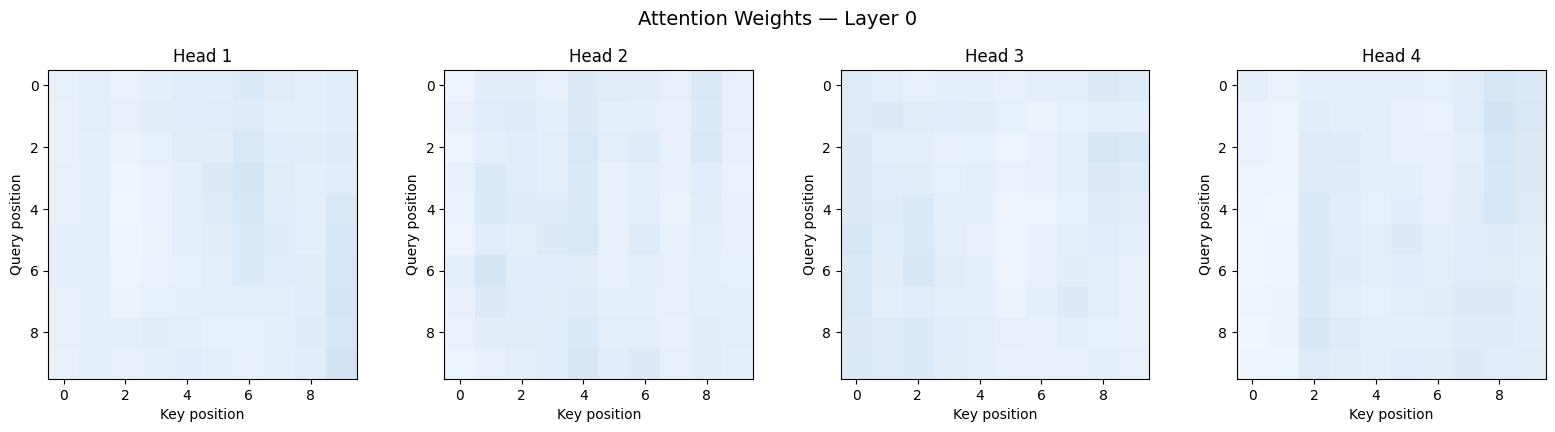

Each head learns different attention patterns!
(With random weights, patterns are random. After training, they become meaningful.)


In [ ]:
def plot_attention_heads(attn_weights, tokens=None, layer=0):
    """Visualize attention weights for each head in a layer."""
    weights = attn_weights[f'layer_{layer}'].numpy()[0]  # First sequence
    num_heads = weights.shape[0]

    fig, axes = plt.subplots(1, num_heads, figsize=(4 * num_heads, 4))
    if num_heads == 1:
        axes = [axes]

    for i, ax in enumerate(axes):
        im = ax.imshow(weights[i], cmap='Blues', vmin=0, vmax=1)
        ax.set_title(f'Head {i+1}')
        ax.set_xlabel('Key position')
        ax.set_ylabel('Query position')
        if tokens:
            ax.set_xticks(range(len(tokens)))
            ax.set_xticklabels(tokens, rotation=45, ha='right')
            ax.set_yticks(range(len(tokens)))
            ax.set_yticklabels(tokens)

    plt.suptitle(f'Attention Weights — Layer {layer}', fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

# Plot attention for our test encoder
plot_attention_heads(enc_attn, layer=0)
print("Each head learns different attention patterns!")
print("(With random weights, patterns are random. After training, they become meaningful.)")

## 9.8 Attention Complexity: O(n²) Scaling

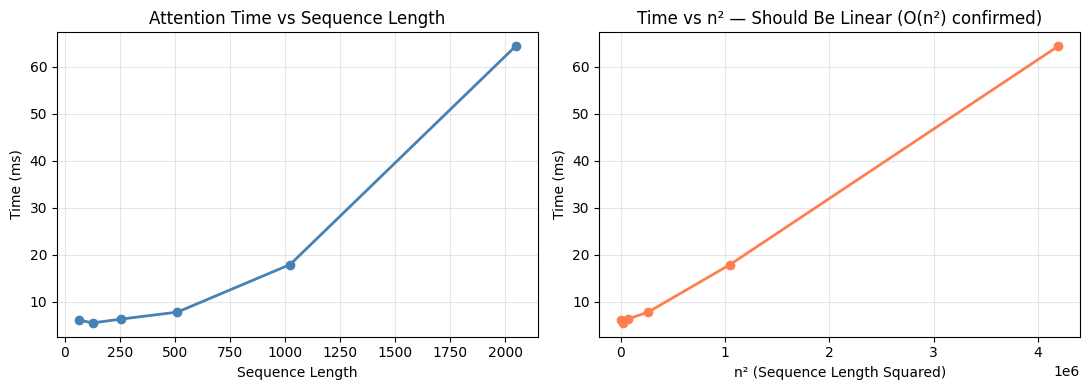

Attention is O(n²) in sequence length — this is why long sequences are expensive!


In [ ]:
# Demonstrate the O(n²) scaling of attention
seq_lens = [64, 128, 256, 512, 1024, 2048]
times = []
d = 64

for n in seq_lens:
    Q_ = tf.random.normal((1, 1, n, d))
    K_ = tf.random.normal((1, 1, n, d))
    V_ = tf.random.normal((1, 1, n, d))
    sdpa = ScaledDotProductAttention()
    # Warm-up
    sdpa(Q_, K_, V_)
    start = time.perf_counter()
    for _ in range(20):
        sdpa(Q_, K_, V_)
    times.append((time.perf_counter() - start) / 20 * 1000)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(seq_lens, times, 'o-', color='steelblue', linewidth=2)
axes[0].set_xlabel('Sequence Length')
axes[0].set_ylabel('Time (ms)')
axes[0].set_title('Attention Time vs Sequence Length')
axes[0].grid(True, alpha=0.3)

# Show quadratic fit
axes[1].plot([n**2 for n in seq_lens], times, 'o-', color='coral', linewidth=2)
axes[1].set_xlabel('n² (Sequence Length Squared)')
axes[1].set_ylabel('Time (ms)')
axes[1].set_title('Time vs n² — Should Be Linear (O(n²) confirmed)')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()
print("Attention is O(n²) in sequence length — this is why long sequences are expensive!")

# Section 10: Translation Examples — Why Attention Makes the Difference

Let's see attention in action with two concrete translation scenarios.

**The key experiment:**
1. First, translate English → French (easy: both SVO)
2. Then, translate English → Hindi (hard: SVO → SOV)

This will show exactly **when and why** a fixed context vector fails and attention saves the day.

## 10.1 Example 1: English → French (Easy — Same Word Order)

### The Sentence

```
English (SVO):  "The cat   sits   on the mat"
                 Subject   Verb   Object/Location

French  (SVO):  "Le chat   s'assoit   sur le tapis"
                 Subject   Verb       Object/Location
```

### Why This Is Easy

Both languages follow **Subject-Verb-Object** order. The alignment is nearly one-to-one:

```
Position:    1        2       3      4      5       6
English:    The      cat    sits    on     the     mat
             ↓        ↓       ↓      ↓       ↓       ↓
French:     Le      chat  s'assoit  sur     le    tapis
Position:    1        2       3      4      5       6
```

The decoder outputs words in almost the **same order** as the encoder reads them.

### Attention Weights (What We'd Expect)

When the decoder generates each French word, attention would show:

| Generating (French) | Strongest Attention On (English) | Weight |
|---------------------|----------------------------------|--------|
| "Le" | "The" (pos 1) | ~0.85 |
| "chat" | "cat" (pos 2) | ~0.90 |
| "s'assoit" | "sits" (pos 3) | ~0.80 |
| "sur" | "on" (pos 4) | ~0.85 |
| "le" | "the" (pos 5) | ~0.80 |
| "tapis" | "mat" (pos 6) | ~0.88 |

**The attention pattern is nearly diagonal** — each output word maps to the same-position input word.

> ✅ **Result:** Even a basic Seq2Seq model can handle this reasonably well. The fixed context vector works because the word order doesn't change. Attention helps, but isn't *critical*.

### Simulating English → French Attention

/tmp/ipykernel_4264/2388079503.py:37: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


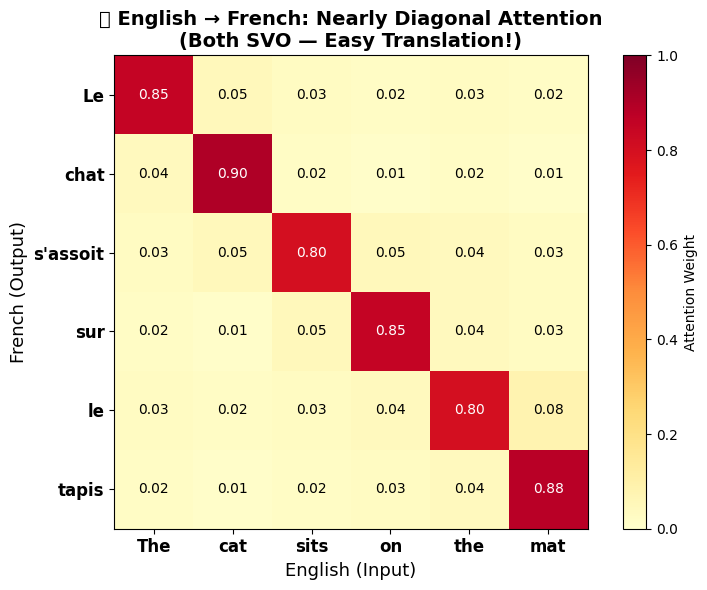

📊 Notice: The attention is nearly DIAGONAL — each French word maps
   directly to the corresponding English word. Easy for any model!


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Simulated attention weights for English → French
english = ["The", "cat", "sits", "on", "the", "mat"]
french  = ["Le", "chat", "s'assoit", "sur", "le", "tapis"]

# Nearly diagonal attention — easy alignment
attn_en_fr = np.array([
    [0.85, 0.05, 0.03, 0.02, 0.03, 0.02],  # Le → The
    [0.04, 0.90, 0.02, 0.01, 0.02, 0.01],  # chat → cat
    [0.03, 0.05, 0.80, 0.05, 0.04, 0.03],  # s'assoit → sits
    [0.02, 0.01, 0.05, 0.85, 0.04, 0.03],  # sur → on
    [0.03, 0.02, 0.03, 0.04, 0.80, 0.08],  # le → the
    [0.02, 0.01, 0.02, 0.03, 0.04, 0.88],  # tapis → mat
])

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(attn_en_fr, cmap='YlOrRd', vmin=0, vmax=1)

ax.set_xticks(range(len(english)))
ax.set_xticklabels(english, fontsize=12, fontweight='bold')
ax.set_yticks(range(len(french)))
ax.set_yticklabels(french, fontsize=12, fontweight='bold')
ax.set_xlabel("English (Input)", fontsize=13)
ax.set_ylabel("French (Output)", fontsize=13)
ax.set_title("✅ English → French: Nearly Diagonal Attention\n(Both SVO — Easy Translation!)",
             fontsize=14, fontweight='bold')

# Annotate each cell
for i in range(len(french)):
    for j in range(len(english)):
        ax.text(j, i, f'{attn_en_fr[i, j]:.2f}', ha='center', va='center',
                fontsize=10, color='white' if attn_en_fr[i, j] > 0.5 else 'black')

plt.colorbar(im, ax=ax, label='Attention Weight')
plt.tight_layout()
plt.show()
print("📊 Notice: The attention is nearly DIAGONAL — each French word maps")
print("   directly to the corresponding English word. Easy for any model!")

## 10.2 Example 2: English → Hindi (Hard — Word Order Reversal!)

### The Sentence

```
English (SVO):  "Ram     eats     food"
                 Subject  Verb    Object    (SVO order)
                   ↓        ╲     ╱
                   ↓         ╳
                   ↓        ╱     ╲
Hindi   (SOV):  "राम     खाना    खाता है"
                 Subject  Object   Verb     (SOV order)
                 (Ram)    (food)   (eats)
```

### Why This Is HARD

The verb and object **swap positions**! The decoder needs to:

| Decoder Step | Generating | Needs to Look At | Problem |
|---|---|---|---|
| Step 1 | "राम" (Ram) | Position 1 (Ram) | ✅ Easy — same position |
| Step 2 | "खाना" (food) | Position 3 (food) | ❌ Must reach BACKWARDS past the verb! |
| Step 3 | "खाता है" (eats) | Position 2 (eats) | ❌ Must reach BACKWARDS to position 2! |

The **crossed lines** are exactly what a fixed context vector cannot handle!

### What Happens WITHOUT Attention (Seq2Seq Only)

```
Encoder reads: "Ram" → "eats" → "food"
                                    ↓
              Context vector: [0.23, -0.15, 0.42, ..., 0.08]  ← ONE vector
                                    ↓
Decoder generates:
  Step 1: "राम"     ← Okay, the subject is usually remembered
  Step 2: "खाता"    ← ERROR! Model outputs verb next (following English order)
  Step 3: "खाना"    ← Too late, word order is wrong!
  
❌ Output: "राम खाता खाना" (Ram eats food — wrong Hindi word order!)
✅ Should be: "राम खाना खाता है" (Ram food eats-is — correct SOV)
```

The fixed vector can't tell the decoder: "Skip the verb for now, output the object first!"

### What Happens WITH Attention

```
Step 1: Generate "राम" (Ram)
  → Query: "Who is the subject?"
  → Attention: [0.92, 0.05, 0.03]  ← Strong focus on "Ram" ✅
                 Ram   eats  food

Step 2: Generate "खाना" (food)
  → Query: "What comes next in Hindi? (the object)"
  → Attention: [0.05, 0.10, 0.85]  ← Reaches BACK to "food"! ✅
                 Ram   eats  food

Step 3: Generate "खाता है" (eats)
  → Query: "What's the verb?"
  → Attention: [0.08, 0.82, 0.10]  ← Now picks up "eats" ✅
                 Ram   eats  food
```

> **Attention can "cross the lines"** — it gives each decoder step the freedom to look at ANY input position, regardless of order!

### Simulating English → Hindi Attention

/tmp/ipykernel_4264/175634738.py:50: UserWarning: Glyph 2352 (\N{DEVANAGARI LETTER RA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4264/175634738.py:50: UserWarning: Matplotlib currently does not support Devanagari natively.
  plt.tight_layout()
/tmp/ipykernel_4264/175634738.py:50: UserWarning: Glyph 2366 (\N{DEVANAGARI VOWEL SIGN AA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4264/175634738.py:50: UserWarning: Glyph 2350 (\N{DEVANAGARI LETTER MA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4264/175634738.py:50: UserWarning: Glyph 2326 (\N{DEVANAGARI LETTER KHA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4264/175634738.py:50: UserWarning: Glyph 2344 (\N{DEVANAGARI LETTER NA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_4264/175634738.py:50: UserWarning: Glyph 2340 (\N{DEVANAGARI LETTER TA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ip

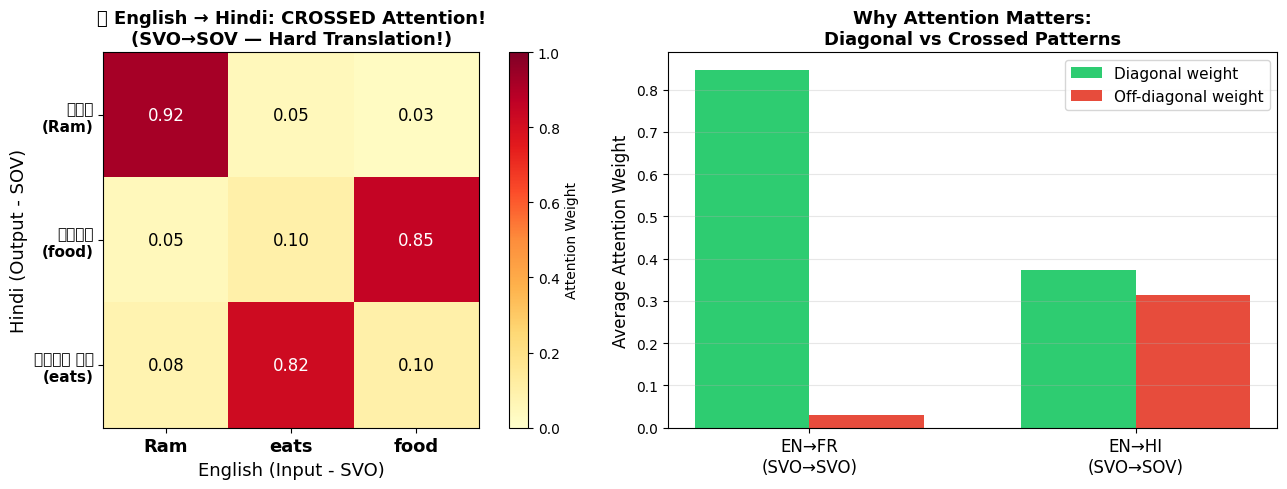

KEY INSIGHT:

🟢 English → French (SVO → SVO):
   Attention is DIAGONAL — words map 1:1 in order.
   Even a fixed context vector works okay here.

🔴 English → Hindi (SVO → SOV):
   Attention CROSSES — verb and object swap!
   A fixed context vector CANNOT do this.
   This is exactly why we need attention!

>>> ATTENTION gives each decoder step the freedom to look
    at ANY input position, regardless of word order! <<<


In [ ]:
# English → Hindi: The crossing attention pattern
english_2 = ["Ram", "eats", "food"]
hindi = ["राम\n(Ram)", "खाना\n(food)", "खाता है\n(eats)"]

# Non-diagonal attention — the crosses!
attn_en_hi = np.array([
    [0.92, 0.05, 0.03],  # राम → Ram        (pos 1→1, easy)
    [0.05, 0.10, 0.85],  # खाना → food       (pos 2→3, CROSS!)
    [0.08, 0.82, 0.10],  # खाता है → eats    (pos 3→2, CROSS!)
])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: The attention heatmap
im = axes[0].imshow(attn_en_hi, cmap='YlOrRd', vmin=0, vmax=1)
axes[0].set_xticks(range(len(english_2)))
axes[0].set_xticklabels(english_2, fontsize=13, fontweight='bold')
axes[0].set_yticks(range(len(hindi)))
axes[0].set_yticklabels(hindi, fontsize=11, fontweight='bold')
axes[0].set_xlabel("English (Input - SVO)", fontsize=13)
axes[0].set_ylabel("Hindi (Output - SOV)", fontsize=13)
axes[0].set_title("❌ English → Hindi: CROSSED Attention!\n(SVO→SOV — Hard Translation!)",
                  fontsize=13, fontweight='bold')

for i in range(len(hindi)):
    for j in range(len(english_2)):
        axes[0].text(j, i, f'{attn_en_hi[i, j]:.2f}', ha='center', va='center',
                    fontsize=12, color='white' if attn_en_hi[i, j] > 0.5 else 'black')

plt.colorbar(im, ax=axes[0], label='Attention Weight')

# Plot 2: Side-by-side comparison
categories = ['Diagonal\n(Easy)', 'Crossed\n(Hard)']
en_fr_diag = np.mean(np.diag(attn_en_fr))
en_hi_diag = np.mean(np.diag(attn_en_hi))
off_diag_fr = np.mean(attn_en_fr[~np.eye(6, dtype=bool)])
off_diag_hi = np.mean(attn_en_hi[~np.eye(3, dtype=bool)])

x = np.arange(2)
width = 0.35
bars1 = axes[1].bar(x - width/2, [en_fr_diag, en_hi_diag], width, label='Diagonal weight', color='#2ecc71')
bars2 = axes[1].bar(x + width/2, [off_diag_fr, off_diag_hi], width, label='Off-diagonal weight', color='#e74c3c')
axes[1].set_xticks(x)
axes[1].set_xticklabels(['EN→FR\n(SVO→SVO)', 'EN→HI\n(SVO→SOV)'], fontsize=12)
axes[1].set_ylabel('Average Attention Weight', fontsize=12)
axes[1].set_title('Why Attention Matters:\nDiagonal vs Crossed Patterns', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=11)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("=" * 60)
print("KEY INSIGHT:")
print("=" * 60)
print()
print("🟢 English → French (SVO → SVO):")
print("   Attention is DIAGONAL — words map 1:1 in order.")
print("   Even a fixed context vector works okay here.")
print()
print("🔴 English → Hindi (SVO → SOV):")
print("   Attention CROSSES — verb and object swap!")
print("   A fixed context vector CANNOT do this.")
print("   This is exactly why we need attention!")
print()
print(">>> ATTENTION gives each decoder step the freedom to look")
print("    at ANY input position, regardless of word order! <<<")

## 10.3 The Complete Picture

### Without Attention (Fixed Context Vector)
```
Works for:     EN→FR  (same word order)        ✅
Fails for:     EN→HI  (different word order)    ❌
Fails for:     Long sentences (>20 words)       ❌
```

### With Attention (Dynamic Context)
```
Works for:     EN→FR  (same word order)        ✅ Even better!
Works for:     EN→HI  (different word order)    ✅ Handles crossing!
Works for:     Long sentences                   ✅ Each step focuses on relevant parts
```

> **Bottom line:** Attention isn't just an improvement — for tasks involving word reordering or long-range dependencies, it's **essential**. The English→Hindi example makes this crystal clear: you simply cannot translate SVO to SOV with a fixed-size summary.

# Section 11: Summary & Quick Reference

## 11.1 The Journey We Took

```
Section 1:  THE PROBLEM          → Fixed context vector bottleneck in Seq2Seq
Section 2:  WHAT IS ATTENTION    → Library analogy, Q/K/V, four steps
Section 3:  HISTORY              → Bahdanau (2015) → Luong (2015) → Transformer (2017)
Section 4:  THE MATH             → Score functions, softmax, weighted sum, matrix form
Section 5:  SELF-ATTENTION       → Same-sequence attention, full numerical walkthrough
Section 6:  MULTI-HEAD           → Multiple perspectives, concatenation
Section 7:  POSITIONAL ENCODING  → Sinusoidal encoding for word order
Section 8:  ENCODER-DECODER      → Full Transformer architecture
Section 9:  KERAS CODE           → ScaledDotProduct → MultiHead → TransformerEncoder
Section 10: EXAMPLES             → EN→FR (easy, diagonal) vs EN→HI (hard, crossed)
```

## 11.2 The Most Important Formula

$$\boxed{\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right) V}$$

## 11.3 Key Takeaways

| Concept | One-Line Summary |
|---------|-----------------|
| **Attention** | Dynamic, learnable lookup into all input positions |
| **Q, K, V** | Query = what I want, Key = what I offer, Value = what I give |
| **Self-attention** | Every token attends to every other token in the same sequence |
| **Multi-head** | Multiple attention heads capture different relationship types |
| **Positional encoding** | Sine/cosine signals that inject word order information |
| **Transformer** | Encoder-decoder model built entirely from attention + FFN |
| **Scaling (√dₖ)** | Prevents softmax saturation in high dimensions |
| **Masking** | Prevents decoder from cheating by looking at future tokens |


---

### References

1. **Sutskever et al. (2014)** — "Sequence to Sequence Learning with Neural Networks" — *The original Seq2Seq*
2. **Bahdanau et al. (2015)** — "Neural Machine Translation by Jointly Learning to Align and Translate" — *Additive attention*
3. **Luong et al. (2015)** — "Effective Approaches to Attention-based Neural Machine Translation" — *Dot-product attention*
4. **Vaswani et al. (2017)** — "Attention Is All You Need" — *The Transformer*

---